# 02 — Mesurer la qualité d'un modèle : de la likelihood à la loss

**Chapitre 1** · durée conseillée : 25 min · CPU uniquement · [![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/chapitre_1/02_mesurer_la_loss.ipynb)

![Parcours du chapitre](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/chapitre_1/figures/00_parcours.png)

**Ce que nous savons faire :** compter les transitions, obtenir une table `P`, puis générer des prénoms.

**Ce qui nous manque :** dire **objectivement** si une table de probabilités est meilleure qu'une autre. « Les prénoms ont l'air jolis » n'est pas une mesure.

Nous allons construire un **thermomètre de qualité** : un seul nombre, qui mesure à quel point les prédictions d'un modèle sont compatibles avec les vrais prénoms.

> **Pourquoi c'est indispensable pour la suite :** au notebook 03, nous remplacerons `P` par une matrice de poids `W` tirée au hasard. Pour l'entraîner, il faudra un nombre à **minimiser**. C'est ce nombre que nous construisons ici : la **loss**.

**Le chemin, en cinq étapes :**
1. regarder la probabilité donnée à la **bonne réponse** ;
2. l'étendre à toutes les lettres d'un prénom : la *likelihood* ;
3. passer du produit à une somme : la *log-likelihood* ;
4. changer le signe pour obtenir un coût : la *negative log-likelihood* (NLL) ;
5. moyenner sur tout le corpus : **la loss**.

In [ ]:
# Sur Google Colab : récupérer le dépôt du cours (corpus + modules partagés comme bigramme.py).
# En local, cette cellule ne fait rien.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("bigramme.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/chapitre_1

In [1]:
# Préparation : imports et petit module partagé du chapitre
import math
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

import bigramme  # fichier bigramme.py, à côté de ce notebook
from bigramme import SEED, plot_matrice_caracteres

words = bigramme.charger_prenoms()
chars, stoi, itos = bigramme.construire_vocabulaire(words)
print(f"{len(words):,} prénoms · vocabulaire de {len(stoi)} symboles · PyTorch {torch.__version__}")

N = bigramme.compter_bigrammes(words, stoi)
P = N.float() / N.sum(dim=1, keepdim=True)     # la table du notebook 01

32,033 prénoms · vocabulaire de 27 symboles · PyTorch 2.14.1+cu130


## 1. Un test plus fiable : la probabilité de la bonne réponse

Posons une question au modèle : **« je suis au début d'un prénom (`.`) ; quelle est la première lettre ? »**

Le modèle ne répond pas « `e` ». Il propose **27 probabilités**, une par caractère possible. Pour le prénom `emma`, la vraie réponse est `e`.

Première mesure : **quelle probabilité le modèle a-t-il donnée à la vraie réponse ?**

$$
\underbrace{P(e\mid .)}_{\text{probabilité de la vraie réponse}}
=\frac{\overbrace{N[\texttt{.},\texttt{e}]}^{\text{prénoms commençant par e}}}{\underbrace{\textstyle\sum_j N[\texttt{.},j]}_{\text{nombre total de prénoms}}}.
$$

In [2]:
i, j = stoi["."], stoi["e"]
print(f"Parmi {N[i].sum().item()} prénoms, {N[i, j].item()} commencent par 'e'.")
print(f"P(e | .) = {P[i, j].item():.4f}   ({100 * P[i, j].item():.2f} %)")
print(f"Un modèle uniforme donnerait 1/27 = {1/27:.4f}")

Parmi 32033 prénoms, 1531 commencent par 'e'.
P(e | .) = 0.0478   (4.78 %)
Un modèle uniforme donnerait 1/27 = 0.0370


**Attention à l'interprétation :** 0,0478 signifie « environ 4,8 % des prénoms du corpus commencent par `e` ». Ce **n'est pas** la probabilité qu'`emma` soit un bon prénom.

Ici 0,048 > 1/27 ≈ 0,037 : sur cette question, le modèle fait un peu mieux que le hasard. Mais une seule question ne suffit pas à juger : il faut regarder **toutes** les prédictions.

## 2. Un prénom contient plusieurs prédictions : la *likelihood*

![Noter le modèle sur emma](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/chapitre_1/figures/02_nll_emma.png)

Pour `emma`, le modèle répond à **cinq questions** :
` . → e ` · ` e → m ` · ` m → m ` · ` m → a ` · ` a → . `

Pour obtenir la probabilité que le modèle attribue à **toute** la séquence `.emma.`, on **multiplie** les cinq probabilités conditionnelles. C'est la règle de probabilité d'une suite d'événements. Dans un bigramme, chaque facteur ne dépend que du caractère précédent :

$$
L(\texttt{emma}) = P(e\mid .)\,P(m\mid e)\,P(m\mid m)\,P(a\mid m)\,P(.\mid a).
$$

La *likelihood* (vraisemblance) est la probabilité que **notre modèle** attribue à cette séquence exacte. Elle ne dit pas si le prénom est « beau ». Elle permet de **comparer deux modèles sur la même observation**.

In [3]:
sequence = ["."] + list("emma") + ["."]
probabilites, labels = [], []

print("Transition | nombre / total | p(bonne réponse)")
print("-" * 48)
for ch1, ch2 in zip(sequence, sequence[1:]):
    i, j = stoi[ch1], stoi[ch2]
    p = P[i, j].item()
    probabilites.append(p)
    labels.append(f"{ch1} → {ch2}")
    print(f"  {ch1} → {ch2}    | {N[i, j].item():5d} / {N[i].sum().item():5d} | {p:.4f}")

likelihood_emma = math.prod(probabilites)
print(f"\nLikelihood L('emma')         = {likelihood_emma:.3e}")
print(f"Likelihood, modèle uniforme  = {(1/27)**5:.3e}")
print(f"Notre table rend 'emma' {likelihood_emma / (1/27)**5:.0f} fois plus probable que l'uniforme.")

Transition | nombre / total | p(bonne réponse)
------------------------------------------------
  . → e    |  1531 / 32033 | 0.0478
  e → m    |   769 / 20423 | 0.0377
  m → m    |   168 /  6642 | 0.0253
  m → a    |  2590 /  6642 | 0.3899
  a → .    |  6640 / 33885 | 0.1960

Likelihood L('emma')         = 3.478e-06
Likelihood, modèle uniforme  = 6.969e-08
Notre table rend 'emma' 50 fois plus probable que l'uniforme.


## 3. Pourquoi passer au logarithme ?

On voudrait **maximiser** la likelihood de **tout le corpus** : le produit des probabilités de ses 228 146 transitions. Mais multiplier des centaines de milliers de nombres plus petits que 1 donne un résultat si petit que l'ordinateur ne peut plus le représenter. On dit qu'il **s'arrondit à zéro** (*underflow*). Faisons l'essai.

In [4]:
xs_all, ys_all = bigramme.construire_exemples(words, stoi)
p_vraies = P[xs_all, ys_all]          # la probabilité de chaque vraie transition du corpus

for n in [10, 100, 1000, len(p_vraies)]:
    produit = torch.prod(p_vraies[:n])
    somme_logs = p_vraies[:n].log().sum()
    print(f"{n:>7} transitions : produit = {produit.item():.3e}   somme des log = {somme_logs.item():12.2f}")

     10 transitions : produit = 3.191e-12   somme des log =       -26.47
    100 transitions : produit = 0.000e+00   somme des log =      -239.92
   1000 transitions : produit = 0.000e+00   somme des log =     -2371.76
 228146 transitions : produit = 0.000e+00   somme des log =   -559873.62


Dès 100 transitions, le produit vaut **0** en float32 : il ne permet plus de comparer quoi que ce soit. La somme des logarithmes, elle, reste un nombre parfaitement lisible.

C'est la propriété clé du logarithme :

$$
\log(a\times b\times c) = \log a+\log b+\log c
\qquad\Rightarrow\qquad
\log L(\texttt{emma}) = \log P(e\mid .)+\log P(m\mid e)+\cdots+\log P(.\mid a).
$$

**Trois bonnes raisons de passer au log :**
1. **Stabilité numérique :** une somme ne s'écrase pas à zéro.
2. **On ne change pas le classement des modèles :** `log` est strictement croissant. Si `L_A > L_B` alors `log L_A > log L_B`.
3. **Plus simple à dériver :** la dérivée d'une somme est la somme des dérivées. Ce sera précieux au notebook 05.

**Pourquoi ces logarithmes sont-ils négatifs ?** Les probabilités sont entre 0 et 1. Or `log(1) = 0` et `log(0,1) ≈ −2,30`. Plus la probabilité de la bonne réponse est petite, plus son logarithme est négatif.

In [5]:
log_likelihood_emma = sum(math.log(p) for p in probabilites)
print(f"log de la likelihood       : {math.log(likelihood_emma):+.4f}")
print(f"somme des log-probabilités : {log_likelihood_emma:+.4f}   (identiques)")

log de la likelihood       : -12.5690
somme des log-probabilités : -12.5690   (identiques)


## 4. Un score à maximiser devient une *loss* à minimiser

On souhaite **maximiser** la log-likelihood. Mais la descente de gradient (notebook 05) **minimise** un coût. On change simplement le signe :

$$
\boxed{\text{coût d'une transition observée} = -\log(p_\text{vraie réponse})}
$$

C'est la **negative log-likelihood (NLL)**.

| p de la vraie réponse | coût `−log p` | interprétation |
|---:|---:|---|
| 1,00 | 0,00 | le modèle était certain de la bonne réponse |
| 0,80 | 0,22 | il la jugeait très plausible |
| 0,10 | 2,30 | il la jugeait peu plausible |
| 0,01 | 4,61 | il a été très surpris |
| → 0 | → ∞ | il la jugeait impossible |

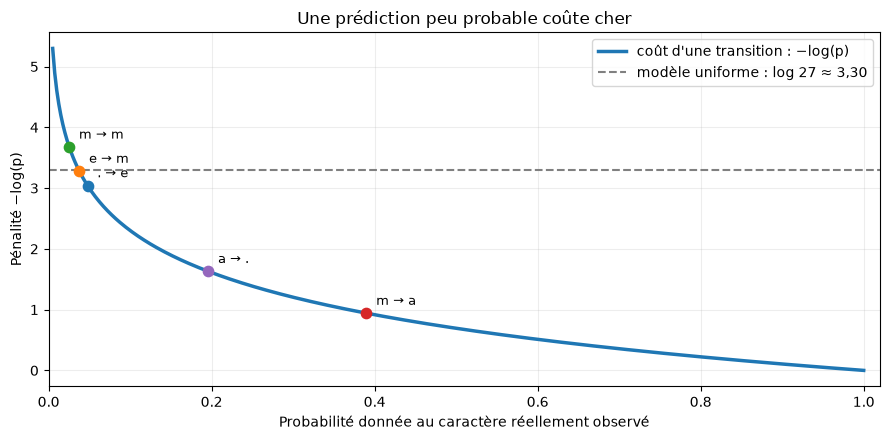

In [6]:
p_grid = torch.linspace(0.005, 1, 400)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(p_grid.numpy(), -p_grid.log().numpy(), linewidth=2.5, label="coût d'une transition : −log(p)")
for label, p in zip(labels, probabilites):
    ax.scatter(p, -math.log(p), s=55, zorder=4)
    ax.annotate(label, (p, -math.log(p)), xytext=(7, 6), textcoords="offset points", fontsize=9)
ax.axhline(math.log(27), color="gray", linestyle="--", label="modèle uniforme : log 27 ≈ 3,30")
ax.set(xlabel="Probabilité donnée au caractère réellement observé", ylabel="Pénalité −log(p)",
       title="Une prédiction peu probable coûte cher", xlim=(0, 1.02))
ax.grid(alpha=0.22); ax.legend(); plt.tight_layout(); plt.show()

**Question :** sur quelles transitions d'`emma` le modèle est-il le plus pénalisé ? Sur `m → m`, `e → m` et `. → e`, auxquelles il donne une faible probabilité. La transition `m → m` coûte même plus cher qu'avec un modèle uniforme (3,68 > 3,30) : un double `m` est rare dans le corpus.

## 5. Un score unique sur tout le corpus : la NLL moyenne

On procède comme pour un examen à beaucoup de questions :
1. pour **chaque transition réelle** du corpus, lire la probabilité de la vraie réponse dans `P` ;
2. calculer son coût `−log p` ;
3. **moyenner**, pour obtenir un score par prédiction qui ne grossit pas avec la taille du corpus.

$$
\boxed{\mathcal{L}(P)=-\frac{1}{M}\sum_{t=1}^{M}\log P(y_t\mid x_t)}
$$

- `M` : nombre total de **bigrammes** observés (pas le nombre de prénoms) ;
- `x_t` : caractère courant de la transition `t` ; `y_t` : le vrai caractère suivant.

**Plus la NLL moyenne est faible, meilleur est le modèle.** Pour savoir si notre score est bon, on le compare au modèle **uniforme**, dont la loss vaut toujours `−log(1/27) = log 27 ≈ 3,30`.

In [7]:
nll_totale, M = 0.0, 0
for prenom in words:
    sequence = ["."] + list(prenom) + ["."]
    for ch1, ch2 in zip(sequence, sequence[1:]):
        nll_totale += -math.log(P[stoi[ch1], stoi[ch2]].item())
        M += 1

loss_comptage = nll_totale / M
print(f"Transitions évaluées     : {M:,}")
print(f"Loss du modèle uniforme  : {math.log(27):.4f}")
print(f"Loss de notre table P    : {loss_comptage:.4f}")

# La même chose en une ligne, sans boucle Python (nous détaillerons cette indexation au notebook 05) :
print(f"Version vectorisée       : {-P[xs_all, ys_all].log().mean().item():.4f}")

Transitions évaluées     : 228,146
Loss du modèle uniforme  : 3.2958
Loss de notre table P    : 2.4540
Version vectorisée       : 2.4540


La table `P` obtient **2,45**, contre **3,30** pour l'uniforme. Attention : ce score est mesuré **sur les données qui ont servi à compter**. Ce n'est pas encore une preuve que le modèle **généralise** à des prénoms qu'il n'a jamais vus (on séparera train et validation au chapitre 2).

### Une autre lecture : la perplexité

`exp(loss)` s'appelle la **perplexité**. On peut la lire comme le nombre de caractères entre lesquels le modèle hésite « en moyenne » à chaque prédiction.

In [8]:
print(f"Perplexité uniforme : {math.exp(math.log(27)):.1f}  (hésite entre 27 caractères)")
print(f"Perplexité de P     : {math.exp(loss_comptage):.1f}  (hésite comme entre ~{math.exp(loss_comptage):.0f} caractères)")

Perplexité uniforme : 27.0  (hésite entre 27 caractères)
Perplexité de P     : 11.6  (hésite comme entre ~12 caractères)


## 6. Le piège du zéro, et le lissage

Que se passe-t-il pour un prénom qui contient une transition **jamais vue** dans le corpus ? Le comptage vaut 0, donc la probabilité vaut 0, et le coût `−log 0` est **infini**.

In [9]:
def nll_prenom(prenom, table):
    seq = ["."] + list(prenom) + ["."]
    couts = [-math.log(table[stoi[a], stoi[b]].item()) if table[stoi[a], stoi[b]] > 0 else float("inf")
             for a, b in zip(seq, seq[1:])]
    return sum(couts) / len(couts)

print("N['j', 'q'] =", N[stoi['j'], stoi['q']].item())
print("NLL de 'andrejq' avec P :", nll_prenom("andrejq", P))

N['j', 'q'] = 0
NLL de 'andrejq' avec P : inf


Un seul bigramme inconnu rend la loss infinie : le modèle déclare « impossible » quelque chose qui est arrivé. La parade classique s'appelle le **lissage** (*smoothing*). On ajoute un **faux comptage** à toutes les cases, par exemple `N + 1` (lissage de Laplace). Aucune probabilité n'est alors nulle.

In [10]:
P_lisse = (N + 1).float() / (N + 1).sum(dim=1, keepdim=True)
print("NLL de 'andrejq' avec P lissée :", round(nll_prenom("andrejq", P_lisse), 4))
print("Loss sur le corpus, P          :", round(-P[xs_all, ys_all].log().mean().item(), 4))
print("Loss sur le corpus, P lissée   :", round(-P_lisse[xs_all, ys_all].log().mean().item(), 4))
for k in [10, 1000, 100_000]:
    Pk = (N + k).float() / (N + k).sum(dim=1, keepdim=True)
    print(f"  lissage +{k:<7} : loss = {-Pk[xs_all, ys_all].log().mean().item():.4f}")

NLL de 'andrejq' avec P lissée : 3.4834
Loss sur le corpus, P          : 2.454
Loss sur le corpus, P lissée   : 2.4546
  lissage +10      : loss = 2.4621
  lissage +1000    : loss = 2.8523
  lissage +100000  : loss = 3.2837


Le lissage +1 ne coûte presque rien sur le corpus (2,4546 au lieu de 2,4540), et supprime les infinis. Plus on ajoute de faux comptages, plus chaque ligne se rapproche de l'**uniforme**, et plus la loss remonte vers 3,30. Nous retrouverons cette idée au notebook 06, sous le nom de **régularisation**.

## Bilan : le lien essentiel avec la suite

Nous avons maintenant **deux choses distinctes** :
- **un modèle** (`P`) : pour un caractère courant, il prédit 27 probabilités ;
- **un critère** (la NLL moyenne) : à partir de ces probabilités et des **vraies réponses**, il produit un seul nombre.

La table `P` a été obtenue en comptant : **rien n'a été entraîné**.

**La question qui lance la suite :** et si les probabilités ne venaient plus de comptages, mais d'une matrice de poids `W` tirée au hasard ? **Comment modifier `W` pour diminuer cette même loss ?**

> La loss n'est pas une particularité du bigramme. C'est **le signal d'apprentissage** que nous réutiliserons quand les probabilités seront produites par un réseau de neurones, puis par un Transformer (au chapitre 2, `F.cross_entropy` calcule exactement cette NLL moyenne).

## Références
- D. Jurafsky et J. H. Martin, [*Speech and Language Processing*](https://web.stanford.edu/~jurafsky/slp3/), chapitre 3 : évaluation par perplexité (3.3) et lissage de Laplace (3.6).
- I. Goodfellow, Y. Bengio et A. Courville, [*Deep Learning*](https://www.deeplearningbook.org/), 2016, section 5.5 « Maximum Likelihood Estimation ».
- Andrej Karpathy, [*The spelled-out intro to language modeling: building makemore*](https://www.youtube.com/watch?v=PaCmpygFfXo) (2022) et le dépôt [makemore](https://github.com/karpathy/makemore), dont viennent `names.txt` et l'esprit de ce chapitre.